In [1]:
import numpy as np
import corner
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

In [22]:
lightcurves = pd.read_csv('imposter_gp_lightcurves.csv')

imposter1 = lightcurves[lightcurves["obj_id"] == 'ZTF18abffyqp']

t_ref = imposter1['mjd'].tolist()
t_0 = imposter1['mjd_0'].tolist()
lum1 = imposter1['mag_ztfi'].to_numpy()
lum2 = imposter1['mag_ztfr'].to_numpy()
lum3 = imposter1['mag_ztfg'].to_numpy()

t_ref = np.array(t_ref)
t_0 = np.array(t_0)
#lum1 = np.array(lum1)
lum2 = np.array(lum2)
lum3 = np.array(lum3)

t = t_ref - t_0


print(lum3)

[18.21905512 18.21722411 18.21544247 18.21371526 18.21204796 18.21044626
 18.20891581 18.20746228 18.20609132 18.20480857 18.2036197  18.20253036
 18.20154621 18.20067294 18.19991626 18.19928191 18.19877565 18.19840329
 18.19817069 18.19808376 18.19814846 18.1983707  18.19875324 18.19929548
 18.19999666 18.20085597 18.20187192 18.20304295 18.20436751 18.20584416
 18.20747147 18.20924811 18.21117277 18.2132442  18.2154612  18.21782261
 18.22032731 18.22297425 18.22576237 18.22869069 18.23175825 18.23496412
 18.2383074  18.24178722 18.24540275 18.24915318 18.25303772 18.2570556
 18.26120608 18.26548844 18.26990197 18.27444597 18.27911978 18.28392273
 18.28885416 18.29391343 18.29909991 18.30441297 18.30985197 18.3154163
 18.32110533 18.32691843 18.33285499 18.33891437 18.34509592 18.351399
 18.35782295 18.3643671  18.37103076 18.37781323 18.38471378 18.39173167
 18.39886613 18.40611637 18.41348156 18.42096085 18.42855335 18.43625814
 18.44407424 18.45200066 18.46003635 18.4681802  18.476

In [23]:
def power_law(t, t_0, M):
    y_vals = M + 3.25 * np.log(t - t_0)
    return y_vals

In [ ]:
init_guess = [np.min(t)-1, np.mean(lum1)]

bounds = ([-np.inf, -np.inf],
          [np.min(t) - 1e-8, np.inf])

#popt_lum1, pcov_lum1 = curve_fit(power_law, t, lum1, p0=init_guess, bounds=bounds)

ValueError: array must not contain infs or NaNs

-4.169986383652816
12.669101367099385


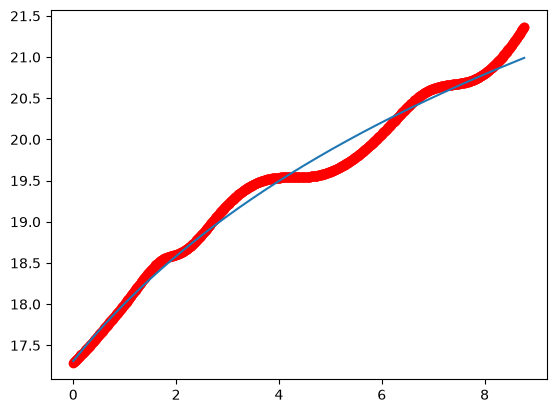

In [ ]:
#t_0_fit_lum1, M_fit_lum1 = popt_lum1

#print(t_0_fit_lum1)
#print(M_fit_lum1)

#y_lum1 = power_law(t, t_0_fit_lum1, M_fit_lum1)

#fig, axs = plt.subplots()
#axs.scatter(t, lum1, color = 'r')
#axs.plot(t, y_lum1)


In [24]:
init_guess = [np.min(t)-1, np.mean(lum2)]

bounds = ([-np.inf, -np.inf],
          [np.min(t) - 1e-8, np.inf])

popt_lum2, pcov_lum2 = curve_fit(power_law, t, lum2, p0=init_guess, bounds=bounds)

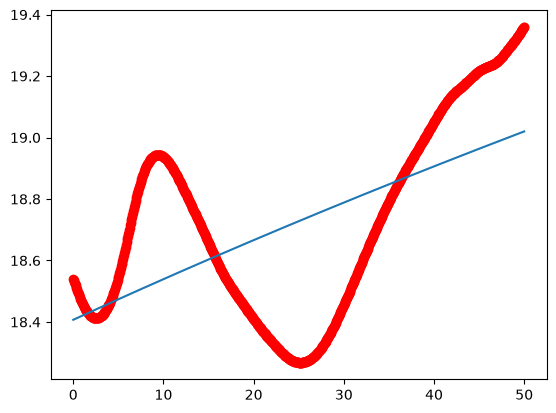

In [25]:
t_0_fit_lum2, M_fit_lum2 = popt_lum2

y_lum2 = power_law(t, t_0_fit_lum2, M_fit_lum2)

fig, axs = plt.subplots()
axs.scatter(t, lum2, color = 'r')
axs.plot(t, y_lum2)


In [27]:
init_guess = [np.min(t)-1, np.mean(lum3)]

bounds = ([-np.inf, -np.inf],
          [np.min(t) - 1e-8, np.inf])

popt_lum3, pcov_lum3 = curve_fit(power_law, t, lum3, p0=init_guess, bounds=bounds)

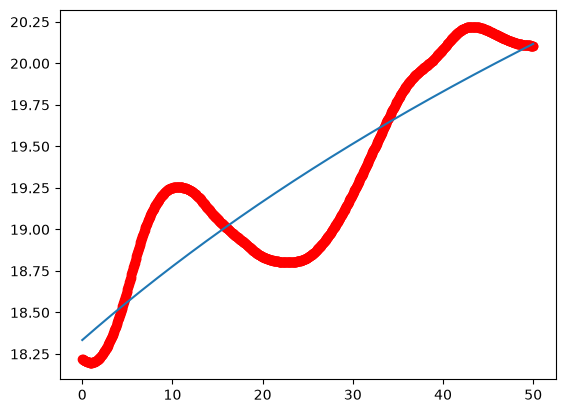

In [29]:
t_0_fit_lum3, M_fit_lum3 = popt_lum3

y_lum3 = power_law(t, t_0_fit_lum3, M_fit_lum3)

fig, axs = plt.subplots()
axs.scatter(t, lum3, color = 'r')
axs.plot(t, y_lum3)


In [30]:
class MetropolisHastings():

    def __init__(self):
        self.theta_chain = []

    def set_proposal_sigma(self, sigma):
        self.proposal_sigma = np.array(sigma)

    def set_target_distribution(self, function):
        self.target_distribution = function

    def initialize(self, theta_init, nsteps):
        self.theta_init = np.array(theta_init)
        self.nsteps = nsteps

    def sample(self):

        self.theta_chain = [self.theta_init.copy()]

        for i in range(self.nsteps):

            theta_prime = np.random.multivariate_normal(mean=self.theta_init, cov=np.diag(self.proposal_sigma**2))

            log_diff = (self.target_distribution(theta_prime) - self.target_distribution(self.theta_init))

            if np.log(np.random.uniform()) < min(0, log_diff):
                self.theta_init = theta_prime

            self.theta_chain.append(self.theta_init.copy())

        return np.array(self.theta_chain)

    def plot_corner(self):
        fig = corner.corner(np.array(self.theta_chain))
        return fig

In [ ]:
#lum1_err = at2017['flux_error_ztfi'].to_numpy()
#lum1_err = np.array(lum1_err)

In [ ]:
def log_likelihood_lum1(theta):

    t_0, M = theta

    if t_0 >= np.min(t):
        return -np.inf

    model = power_law(t, t_0, M)

    return -0.5 * np.sum(((lum1 - model) / lum1_err)**2+ np.log(2 * np.pi * lum1_err**2))

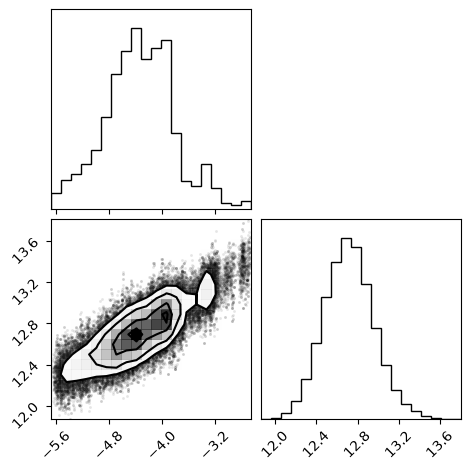

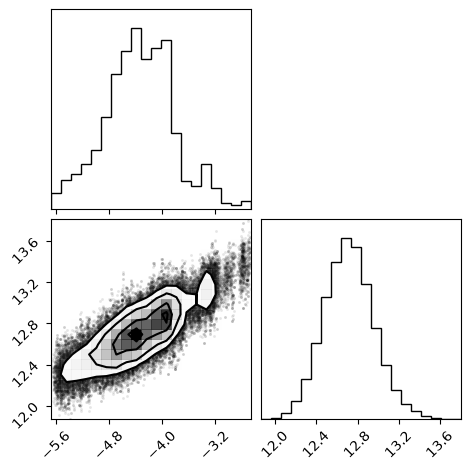

In [ ]:
#sampler = MetropolisHastings()

#sampler.set_proposal_sigma([0.01, 0.1])

#sampler.set_target_distribution(log_likelihood_lum1)

#sampler.initialize(theta_init=[t_0_fit_lum1, M_fit_lum1], nsteps=100000)

#samples = sampler.sample()

#sampler.plot_corner()

In [32]:
lum2_err = at2017['flux_error_ztfr'].to_numpy()
lum2_err = np.array(lum2_err)

In [33]:
def log_likelihood_lum2(theta):

    t_0, M = theta

    if t_0 >= np.min(t):
        return -np.inf

    model = power_law(t, t_0, M)

    return -0.5 * np.sum(((lum2 - model) / lum2_err)**2+ np.log(2 * np.pi * lum2_err**2))

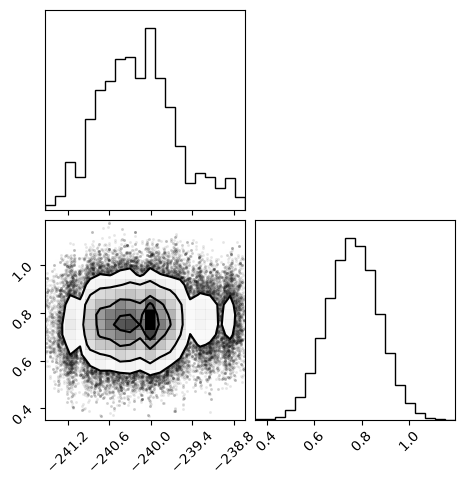

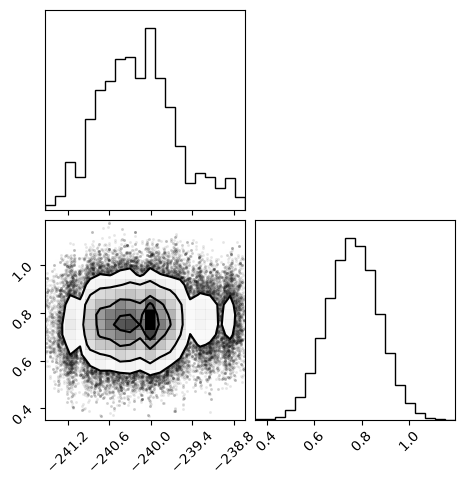

In [34]:
sampler2 = MetropolisHastings()

sampler2.set_proposal_sigma([0.01, 0.1])

sampler2.set_target_distribution(log_likelihood_lum2)

sampler2.initialize(theta_init=[t_0_fit_lum2, M_fit_lum2], nsteps=100000)

samples = sampler2.sample()

sampler2.plot_corner()

In [36]:
lum3_err = at2017['flux_error_ztfg'].to_numpy()
lum3_err = np.array(lum3_err)

In [35]:
def log_likelihood_lum3(theta):

    t_0, M = theta

    if t_0 >= np.min(t):
        return -np.inf

    model = power_law(t, t_0, M)

    return -0.5 * np.sum(((lum3 - model) / lum3_err)**2+ np.log(2 * np.pi * lum3_err**2))

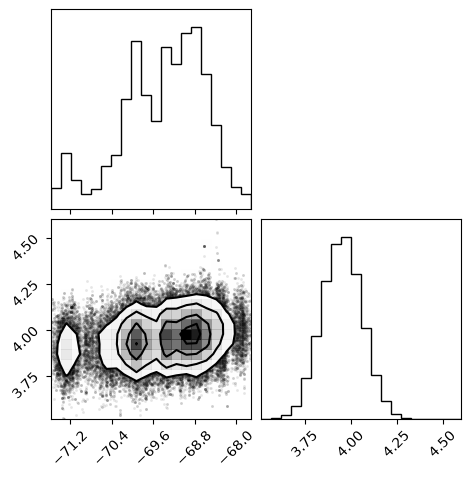

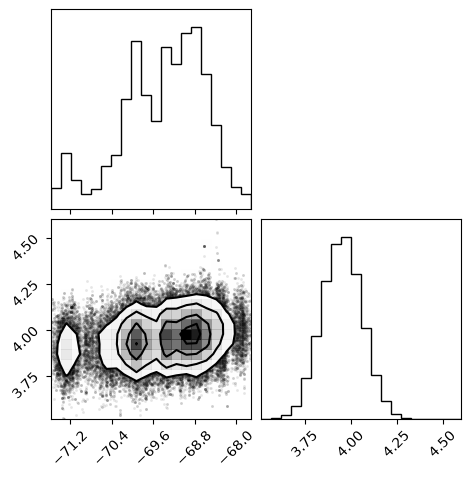

In [37]:
sampler3 = MetropolisHastings()

sampler3.set_proposal_sigma([0.01, 0.1])

sampler3.set_target_distribution(log_likelihood_lum2)

sampler3.initialize(theta_init=[t_0_fit_lum3, M_fit_lum3], nsteps=100000)

samples = sampler3.sample()

sampler3.plot_corner()

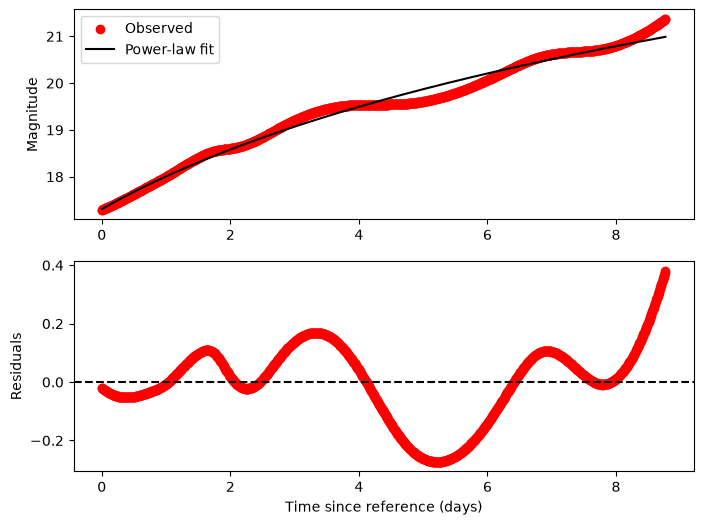

In [ ]:
#residuals_lum1 = lum1 - y_lum1

#fig, axs = plt.subplots(2, 1, figsize=(8,6))

#axs[0].scatter(t, lum1, color='r', label='Observed')
#axs[0].plot(t, y_lum1, color='black', label='Power-law fit')
#axs[0].set_ylabel('Magnitude')
#axs[0].legend()

#axs[1].scatter(t, residuals_lum1, color='r')
#axs[1].axhline(0, color='black', linestyle='--')
#axs[1].set_xlabel('Time since reference (days)')
#axs[1].set_ylabel('Residuals')

#plt.show()

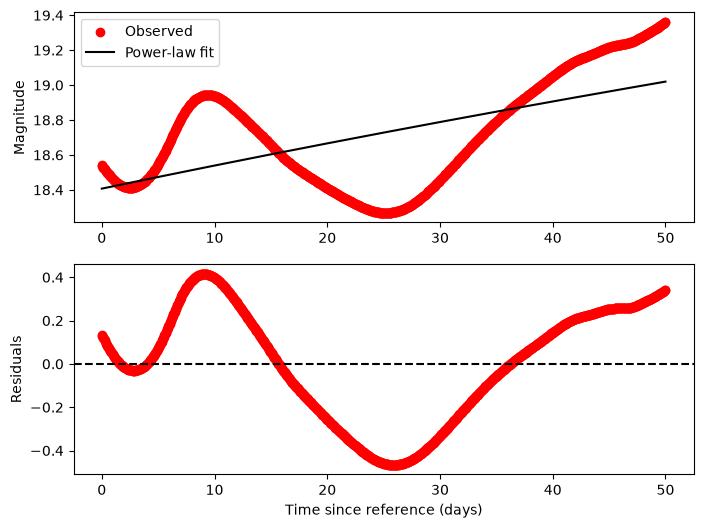

In [38]:
residuals_lum2 = lum2 - y_lum2

fig, axs = plt.subplots(2, 1, figsize=(8,6))

axs[0].scatter(t, lum2, color='r', label='Observed')
axs[0].plot(t, y_lum2, color='black', label='Power-law fit')
axs[0].set_ylabel('Magnitude')
axs[0].legend()

axs[1].scatter(t, residuals_lum2, color='r')
axs[1].axhline(0, color='black', linestyle='--')
axs[1].set_xlabel('Time since reference (days)')
axs[1].set_ylabel('Residuals')

plt.show()

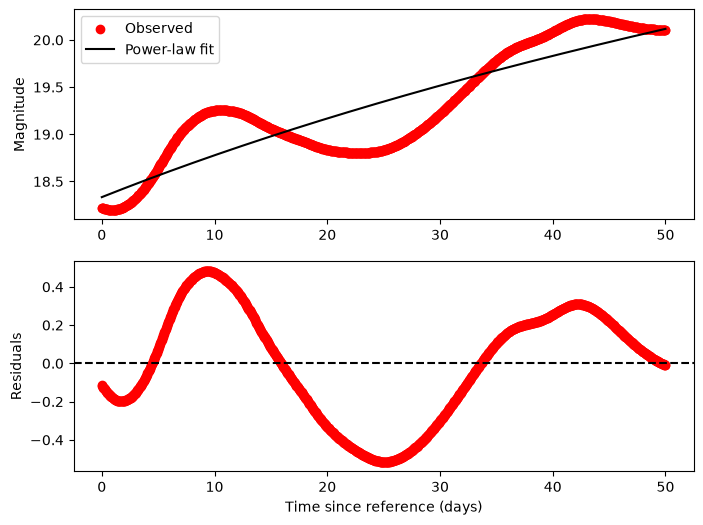

In [41]:
residuals_lum3 = lum3 - y_lum3

fig, axs = plt.subplots(2, 1, figsize=(8,6))

axs[0].scatter(t, lum3, color='r', label='Observed')
axs[0].plot(t, y_lum3, color='black', label='Power-law fit')
axs[0].set_ylabel('Magnitude')
axs[0].legend()

axs[1].scatter(t, residuals_lum3, color='r')
axs[1].axhline(0, color='black', linestyle='--')
axs[1].set_xlabel('Time since reference (days)')
axs[1].set_ylabel('Residuals')

plt.show()